# F1 — Risque de crédit en Allemagne

**IDRISSI AZAMI Marwa** · Code Apogée 25007652 · Groupe G2

## 1. Contexte et problématique

Lors de l'octroi d'un crédit, les établissements financiers doivent évaluer la solvabilité des emprunteurs afin de limiter les défauts de paiement tout en restant compétitifs sur l'acceptation des dossiers. Les erreurs de décision n'ont pas le même impact financier : accepter un client à risque entraîne des pertes directes, tandis que refuser un bon client représente un manque à gagner.

L'analyse des caractéristiques du client et du prêt permet d'estimer la probabilité de défaut et d'ajuster la règle de décision selon les contraintes économiques de la banque.

**Problématique :**

> Quels attributs du client et du prêt permettent d'identifier les mauvais risques, et comment ajuster le seuil de décision d'un modèle de classification binaire face à des coûts d'erreur asymétriques ?

### 1.1 Objectif du projet

L'objectif est de construire et d'évaluer un modèle de Machine Learning capable d'identifier les dossiers à risque à partir des données historiques du jeu German Credit (UCI 144 : 1 000 dossiers, 20 variables, 300 mauvais risques), tout en tenant compte de coûts d'erreur asymétriques.

Pour cela, nous allons :

- Charger et explorer les 1 000 dossiers et 20 variables du jeu German Credit (UCI 144), en documentant la source et les variables.
- Appliquer un prétraitement sans fuite d'information : *One-Hot Encoding* des variables catégorielles et standardisation des variables numériques (notamment les montants et les durées).
- Entraîner une régression logistique (modèle principal) pour estimer la probabilité de mauvais risque, et une forêt aléatoire comme alternative de comparaison. L'hyperparamètre `C` et le seuil de décision sont choisis par validation croisée sur l'entraînement uniquement.
- Comparer les modèles à des références naïves : « tout accepter », « tout refuser » et le seuil standard 0,50.
- Évaluer une seule fois sur le jeu de test : coût total (métrique principale), AUC et rappel des mauvais risques.
- Tracer la courbe de coût selon le seuil de décision et analyser la sensibilité au ratio de coûts (3:1, 5:1 et 8:1).

**Critère de réussite :** le coût total sur le jeu de test doit être inférieur à celui de la meilleure référence naïve.

### 1.2 Nature du problème

- **Type d'apprentissage :** apprentissage supervisé.
- **Tâche :** classification binaire avec coûts d'erreur asymétriques.
- **Algorithme principal :** régression logistique.
- **Alternative comparée :** forêt aléatoire.
- **Références (modèles naïfs) :** tout accepter, tout refuser, seuil standard 0,50.
- **Jeu de données :** German Credit (UCI 144 — 1 000 dossiers, 20 variables, 300 mauvais risques).
- **Métriques d'évaluation :** coût total (principale) ; AUC et rappel des mauvais risques (secondaires) ; analyse de sensibilité du seuil optimal.

### 1.3 Définition de la variable cible et des coûts

La variable cible binaire distingue deux profils de dossiers :

- **Classe 0 :** bon risque de crédit (dossier solvable).
- **Classe 1 :** mauvais risque de crédit (dossier à défaut / risqué).

Les erreurs de prédiction sont pondérées par une matrice de coûts asymétriques. Hypothèse de référence : un faux négatif (mauvais risque accepté) coûte 5 fois un faux positif (bon dossier refusé), soit C_FN = 5 et C_FP = 1. Cette matrice sert à déterminer le seuil de décision qui minimise le coût total et à étudier sa sensibilité (ratios 3:1, 5:1 et 8:1).

## 2. Présentation de l'algorithme : régression logistique

### 2.1 Principe mathématique et fonctionnement

La régression logistique est un modèle linéaire probabiliste dédié à la classification binaire. Contrairement à la régression linéaire, qui prédit une valeur continue dans ℝ, elle modélise directement la probabilité conditionnelle P(Y = 1 | X) qu'un dossier de crédit appartienne à la classe des mauvais risques.

Le modèle opère en deux étapes successives.

**Étape 1 : combinaison linéaire des attributs.** Calcul d'un score brut z pondérant les caractéristiques du client et du prêt :

```
              p
z  =  b  +    Σ   w_j · x_j   =   w^T · X + b
             j=1
```

**Étape 2 : transformation par la fonction sigmoïde.** Projection de z dans l'intervalle [0, 1] afin d'obtenir une probabilité estimée :

```
                      1
p̂  =  σ(z)  =  ───────────────
                  1 + exp(−z)
```

**Règle de décision.** La prédiction finale ŷ ∈ {0, 1} est obtenue en comparant p̂ à un seuil de décision s :

```
ŷ = 1   si   p̂ ≥ s        (on refuse le dossier)
ŷ = 0   si   p̂ < s        (on accepte le dossier)
```

**Symboles :** X : vecteur des p variables d'un dossier après prétraitement ; w_j : poids appris pour la variable j ; x_j : valeur de la variable j ; b : biais (constante) appris ; z : score linéaire ; σ : fonction sigmoïde ; exp : fonction exponentielle ; p̂ : probabilité estimée d'être un mauvais risque ; s : seuil de décision ; w^T : transposée du vecteur des poids.

**Apprentissage.** Les paramètres w et b sont appris en minimisant la perte logistique pénalisée par la norme L2 (forme utilisée par scikit-learn) :

```
               1                   n
  min        ─────  ‖w‖²   +   C · Σ   log( 1 + exp( −ỹ_i · (w^T · x_i + b) ) )
 w, b          2                  i=1
```

où n est le nombre de dossiers d'entraînement, x_i le vecteur du dossier i, ỹ_i sa classe codée −1 ou +1, ‖w‖² la somme des carrés des poids, et C l'inverse de la force de régularisation : un C petit écrase les poids, un C grand laisse le modèle suivre le bruit.

**Seuil de décision.** Si les probabilités sont bien estimées, la décision qui minimise le coût attendu refuse un dossier dès que :

```
p̂ · C_FN  >  (1 − p̂) · C_FP
```

ce qui donne le seuil théorique suivant (ici pour le ratio 5:1) :

```
                C_FP                   1
s_th  =  ─────────────────  =  ─────────  ≈  0,17
          C_FP + C_FN             1 + 5
```

Ce repère théorique sert de contrôle de cohérence du seuil trouvé par validation croisée.

### 2.2 Justification du choix et réponse aux exigences théoriques

- **Modèle principal interprétable :** en credit scoring, la régression logistique constitue le standard bancaire, car chaque coefficient w_j est directement interprétable via le rapport de cotes (*odds ratio* exp(w_j)). Il permet d'identifier clairement les attributs qui augmentent ou réduisent le risque de défaut, et de justifier un refus.
- **Probabilités exploitables :** elle fournit des probabilités utilisables pour déplacer le seuil de décision s et minimiser une matrice de coûts asymétriques. La régularisation L2 rend ces probabilités un peu moins extrêmes ; une calibration (méthode de Platt) reste une amélioration possible.
- **Nécessité du prétraitement :** la pénalité L2 s'applique aux poids. La standardisation des variables numériques (montant, durée) évite qu'une variable pèse plus qu'une autre uniquement à cause de son échelle.
- **Alternative comparée :** la forêt aléatoire capte des interactions non linéaires, mais elle est moins interprétable et plus exposée au surapprentissage sur un petit échantillon (1 000 dossiers).

### 2.3 Deux cas d'usage en finance

- **Octroi de crédit et scoring bancaire (cas F1) :** évaluation de la probabilité de défaut d'un emprunteur à partir de son profil financier et de la structure du prêt, avec optimisation du seuil d'acceptation selon le coût d'un défaut.
- **Détection de fraude et gestion des impayés :** scoring en temps réel des transactions par carte bancaire pour bloquer les opérations dont la probabilité de fraude, ou la perte espérée, dépasse un seuil critique.

### Schéma de la chaîne de décision

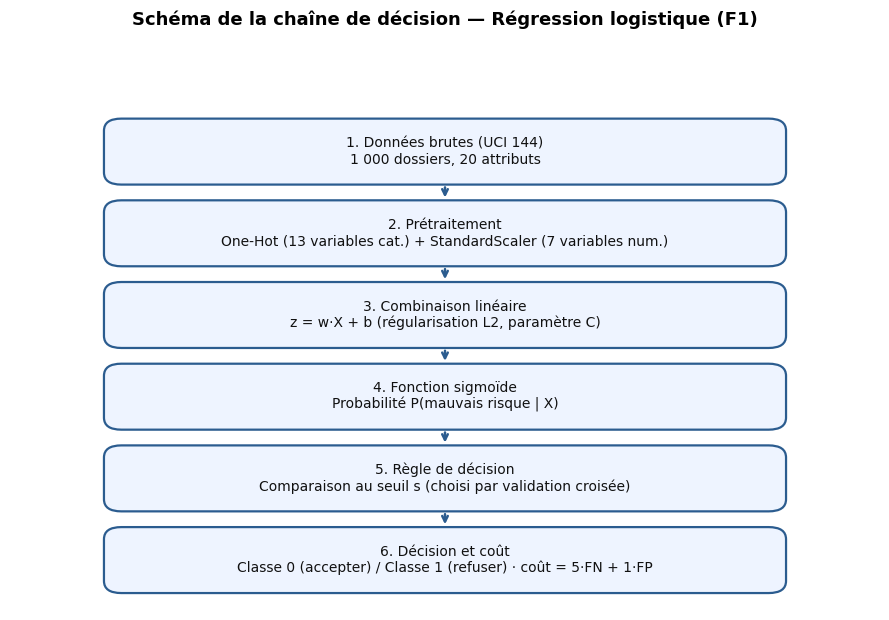

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def flux(etapes, titre="Schéma de flux", boucle=False):
    fig, ax = plt.subplots(figsize=(9, max(4, len(etapes) * 1.05)))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, len(etapes) * 1.4 + 1)
    ax.axis('off')
    ax.set_title(titre, fontsize=13, fontweight='bold', pad=12)

    positions = []
    for i, texte in enumerate(etapes):
        y = (len(etapes) - 1 - i) * 1.35 + 0.4
        box = FancyBboxPatch(
            (1.2, y), 7.6, 0.85,
            boxstyle="round,pad=0.12,rounding_size=0.2",
            facecolor="#eef4ff", edgecolor="#2b5c8f", linewidth=1.6
        )
        ax.add_patch(box)
        ax.text(5.0, y + 0.425, texte, ha='center', va='center', fontsize=10, color="#111")
        positions.append(y)

        if i < len(etapes) - 1:
            y_next = (len(etapes) - 2 - i) * 1.35 + 0.4
            ax.annotate(
                "", xy=(5.0, y_next + 0.97), xytext=(5.0, y - 0.12),
                arrowprops=dict(arrowstyle="->", lw=1.8, color="#2b5c8f")
            )

    if boucle and len(positions) > 1:
        y_top = positions[0] + 0.425
        y_bot = positions[-1] + 0.425
        ax.annotate(
            "", xy=(8.95, y_top), xytext=(8.95, y_bot),
            arrowprops=dict(arrowstyle="->", lw=1.5, linestyle="--", color="#c0392b",
                            connectionstyle="arc3,rad=-0.25")
        )

    plt.tight_layout()
    plt.show()

flux(
    [
        '1. Données brutes (UCI 144)\n1 000 dossiers, 20 attributs',
        '2. Prétraitement\nOne-Hot (13 variables cat.) + StandardScaler (7 variables num.)',
        '3. Combinaison linéaire\nz = w·X + b (régularisation L2, paramètre C)',
        '4. Fonction sigmoïde\nProbabilité P(mauvais risque | X)',
        '5. Règle de décision\nComparaison au seuil s (choisi par validation croisée)',
        '6. Décision et coût\nClasse 0 (accepter) / Classe 1 (refuser) · coût = 5·FN + 1·FP'
    ],
    titre='Schéma de la chaîne de décision — Régression logistique (F1)',
    boucle=False
)

**Interprétation.** Le prétraitement est ajusté sur l'entraînement uniquement et refait dans chaque pli de validation croisée, ce qui évite toute fuite d'information. Le paramètre `C` (étape 3) et le seuil `s` (étape 5) sont choisis par validation croisée sur l'entraînement ; le jeu de test n'est utilisé qu'une seule fois, pour l'évaluation finale (étape 6).

## Description des données

| Élément | Description |
|---|---|
| Nom | Statlog (German Credit Data), UCI n°144 (identique à OpenML *credit-g*, data_id = 31) |
| Organisme | UCI Machine Learning Repository ; jeu constitué par le Prof. Hans Hofmann, université de Hambourg |
| URL | https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data |
| Licence | CC BY 4.0 |
| Date d'extraction | Téléchargé par `fetch_openml(data_id=31)` à chaque exécution (date affichée par la cellule d'exploration ci-dessous) |
| Taille | 1 000 lignes × 20 variables explicatives (7 numériques, 13 catégorielles) + 1 cible |
| Période et fréquence | Jeu historique publié en 1994, sans date par dossier : coupe transversale |
| Unité d'observation | Une demande de crédit (un demandeur) ; montants en Deutsche Mark (DM) |


### Dictionnaire de huit variables clés

| Variable | Rôle | Type | Unité ou modalités | Manquants |
|---|---|---|---|---|
| duration | explicative | numérique | mois (4 à 72) | 0 |
| credit_amount | explicative | numérique | DM (250 à 18 424) | 0 |
| age | explicative | numérique | années (19 à 75) | 0 |
| checking_status | explicative | catégorielle (4) | solde du compte courant | 0 |
| savings_status | explicative | catégorielle (5) | niveau d'épargne | 0 |
| credit_history | explicative | catégorielle (5) | historique de remboursement | 0 |
| purpose | explicative | catégorielle (10) | objet du crédit | 0 |
| class | cible | binaire | 1 = mauvais risque (300), 0 = bon risque (700) | 0 |

Date d'extraction : 2026-11-22
Dimensions : (1000, 20) | mauvais risques : 300
Valeurs manquantes : 0 | doublons : 0
Montants au-dessus de la barrière de Tukey (7882 DM) : 72 | taux de défaut : 0.542


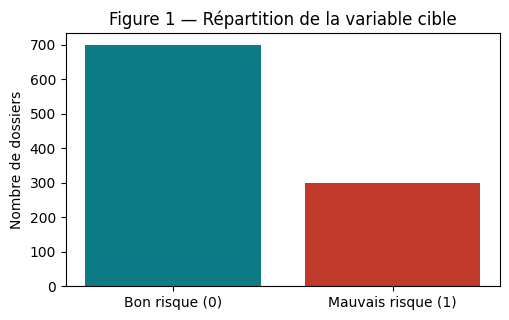

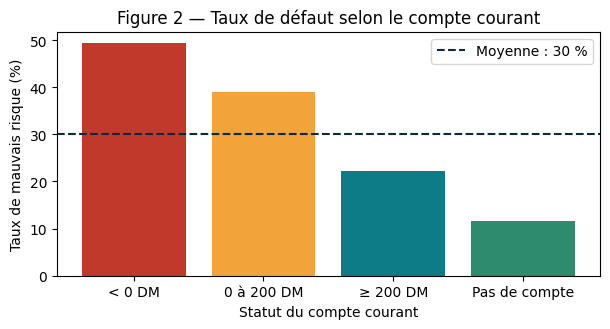

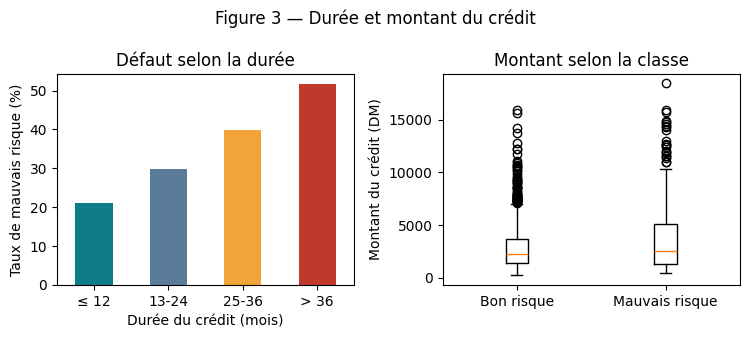

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from datetime import date

credit = fetch_openml(data_id=31, as_frame=True, parser='auto')
X_cred = credit.data
y_cred = (credit.target == 'bad').astype(int)   # 1 = mauvais risque

# --- Qualité des données ---
print("Date d'extraction :", date.today())
print("Dimensions :", X_cred.shape, "| mauvais risques :", int(y_cred.sum()))
print("Valeurs manquantes :", int(X_cred.isna().sum().sum()), "| doublons :", int(X_cred.duplicated().sum()))
q1, q3 = X_cred['credit_amount'].quantile([0.25, 0.75])
barriere = q3 + 1.5 * (q3 - q1)
n_extremes = int((X_cred['credit_amount'] > barriere).sum())
d = X_cred.copy(); d['bad'] = y_cred.values
print(f"Montants au-dessus de la barrière de Tukey ({barriere:.0f} DM) : {n_extremes}"
      f" | taux de défaut : {d[d.credit_amount > barriere].bad.mean():.3f}")

# --- Figure 1 : répartition de la cible ---
fig, ax = plt.subplots(figsize=(5.2, 3.3))
ax.bar(['Bon risque (0)', 'Mauvais risque (1)'], [(d.bad == 0).sum(), (d.bad == 1).sum()], color=['#0E7C86', '#C0392B'])
ax.set_ylabel('Nombre de dossiers')
ax.set_title('Figure 1 — Répartition de la variable cible')
plt.tight_layout(); plt.show()

# --- Figure 2 : taux de défaut selon le compte courant ---
g = d.groupby('checking_status', observed=True)['bad'].mean().reindex(['<0', '0<=X<200', '>=200', 'no checking']) * 100
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.bar(['< 0 DM', '0 à 200 DM', '≥ 200 DM', 'Pas de compte'], g.values, color=['#C0392B', '#F2A33A', '#0E7C86', '#2E8B6E'])
ax.axhline(30, color='#0B2A3C', linestyle='--', label='Moyenne : 30 %')
ax.set_xlabel('Statut du compte courant'); ax.set_ylabel('Taux de mauvais risque (%)')
ax.set_title('Figure 2 — Taux de défaut selon le compte courant'); ax.legend()
plt.tight_layout(); plt.show()

# --- Figure 3 : durée et montant ---
d['tranche_duree'] = pd.cut(d['duration'], [0, 12, 24, 36, 100], labels=['≤ 12', '13-24', '25-36', '> 36'])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.6, 3.4))
(d.groupby('tranche_duree', observed=True)['bad'].mean() * 100).plot.bar(ax=a1, color=['#0E7C86', '#5B7C99', '#F2A33A', '#C0392B'], rot=0)
a1.set_xlabel('Durée du crédit (mois)'); a1.set_ylabel('Taux de mauvais risque (%)'); a1.set_title('Défaut selon la durée')
a2.boxplot([d[d.bad == 0].credit_amount, d[d.bad == 1].credit_amount], tick_labels=['Bon risque', 'Mauvais risque'])
a2.set_ylabel('Montant du crédit (DM)'); a2.set_title('Montant selon la classe')
plt.suptitle('Figure 3 — Durée et montant du crédit'); plt.tight_layout(); plt.show()

**Qualité des données.** Aucune valeur manquante ni aucun doublon. Les 72 montants au-dessus de la barrière de Tukey (7 882 DM) sont conservés : ce sont des crédits réels et leur taux de défaut (54 %) montre qu'ils portent de l'information.

**Figure 1.** Les 1 000 dossiers comptent 700 bons risques et 300 mauvais risques (30 %). Le déséquilibre est modéré mais important pour la décision : un modèle qui accepterait tout aurait 70 % d'exactitude tout en étant le pire sur le plan économique. On utilise donc un découpage stratifié et on juge les modèles sur le coût et l'AUC.

**Figure 2.** Le taux de défaut passe de 49 % pour un solde négatif à 22 % pour un solde d'au moins 200 DM, pour une moyenne de 30 %. Résultat contre-intuitif : les clients sans compte courant sont les plus sûrs (12 %, n = 394), ce qui peut refléter la politique de sélection de la banque. Le modèle retrouve ce signal en section 4.

**Figure 3.** Le risque augmente avec la durée : 21 % jusqu'à 12 mois, 30 % de 13 à 24 mois, 40 % de 25 à 36 mois et 52 % au-delà de 36 mois. Le montant discrimine moins : médiane de 2 575 DM pour les mauvais risques contre 2 244 DM pour les bons, avec une forte asymétrie à droite.

## 3. Implémentation et protocole expérimental

### 3.1 Protocole de validation et matrice de coûts

- **Découpage des données :** séparation stratifiée en 75 % d'entraînement (750 dossiers) et 25 % de test (250 dossiers), avec une graine fixe (`random_state = 42`), afin de conserver la proportion exacte de 30 % de mauvais risques (225 dans l'entraînement, 75 dans le test).
- **Prétraitement sans fuite d'information :** `StandardScaler` et `OneHotEncoder` sont intégrés dans un `Pipeline` ajusté sur l'entraînement uniquement, et refait dans chaque pli de validation croisée.
- **Réglages sur l'entraînement uniquement :** l'hyperparamètre $C$ et le seuil de décision $s$ sont choisis par validation croisée stratifiée à 5 plis sur les 750 dossiers d'entraînement. Le jeu de test n'est utilisé **qu'une seule fois**, pour l'évaluation finale.
- **Références de comparaison :** « tout accepter », « tout refuser » et le seuil standard 0,50.
- **Justification de la matrice de coûts :** dans le secteur du crédit, accepter un client qui fait défaut (faux négatif, $FN$) entraîne la perte d'une grande partie du capital prêté et des frais de recouvrement, alors que refuser un client solvable (faux positif, $FP$) ne représente qu'un manque à gagner sur la marge d'intérêts. Nous fixons donc la matrice de référence à $C_{FN} = 5$

## Entraînement, attributs influents, courbe de coût et sensibilité

Référence « tout accepter » : coût = 375
Référence « tout refuser »  : coût = 175

AUC moyen en validation croisée : {0.01: np.float64(0.757), 0.1: np.float64(0.7735), 0.5: np.float64(0.7669), 1.0: np.float64(0.76), 5.0: np.float64(0.7452), 10.0: np.float64(0.741), 50.0: np.float64(0.7366)}
C retenu : 0.1

AUC sur l'échantillon de test : 0.8107

--- Top 5 des attributs augmentant le risque de défaut ---
                                 Attribut  Coefficient  Odds_Ratio
                 cat__savings_status_<100     0.414061    1.512950
                   cat__purpose_education     0.405550    1.500128
                  cat__checking_status_<0     0.388063    1.474123
cat__property_magnitude_no known property     0.329026    1.389615
                            num__duration     0.293586    1.341229

--- Top 5 des attributs réduisant le risque de défaut ---
                                          Attribut  Coefficient  Odds_Ratio
              cat__savings_status_no known savings    -0

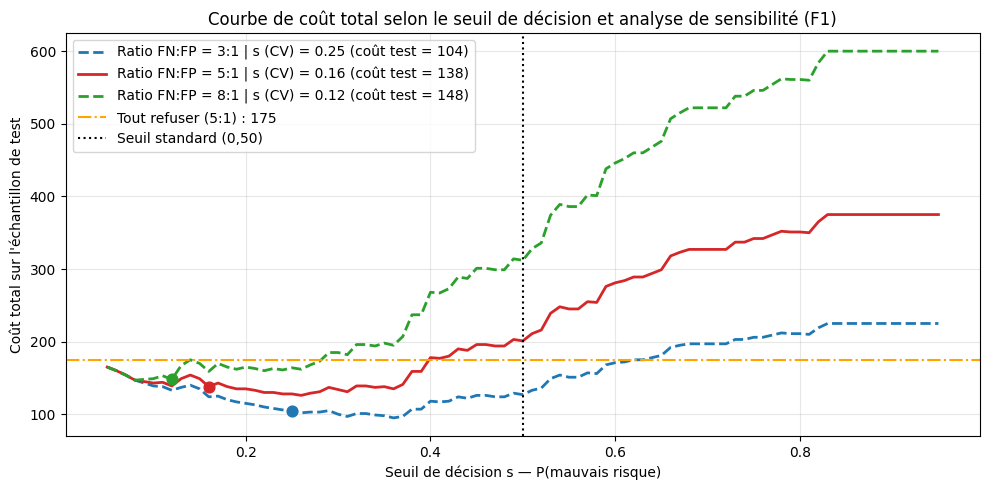

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

SEED = 42

# 1. Chargement du jeu de données German Credit (UCI 144 : 1000 dossiers, 20 variables)
credit = fetch_openml(data_id=31, as_frame=True, parser='auto')
X_cred = credit.data
y_cred = (credit.target == 'bad').astype(int)  # 1 = mauvais risque, 0 = bon risque

X_train, X_test, y_train, y_test = train_test_split(
    X_cred, y_cred, test_size=0.25, random_state=SEED, stratify=y_cred
)

# 2. Prétraitement : encodage des catégorielles et standardisation des numériques
num_cols = X_cred.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_cred.select_dtypes(exclude=['int64', 'float64']).columns.tolist()

preproc = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols)
])

def cout_total(y_true, y_pred, cout_FN=5, cout_FP=1):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    return fn * cout_FN + fp * cout_FP

y_te = y_test.values
y_tr = y_train.values

# 3. Références naïves (ratio 5:1, sur le test)
cout_tout_accepter = cout_total(y_te, np.zeros_like(y_te))
cout_tout_refuser = cout_total(y_te, np.ones_like(y_te))
print(f"Référence « tout accepter » : coût = {cout_tout_accepter}")
print(f"Référence « tout refuser »  : coût = {cout_tout_refuser}\n")

# 4. Choix de C par validation croisée (5 plis) sur l'entraînement uniquement
def modele(C):
    return Pipeline([('prep', preproc),
                     ('clf', LogisticRegression(C=C, max_iter=1000, random_state=SEED))])

liste_C = [0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0]
scores_cv = [cross_val_score(modele(C), X_train, y_train, cv=5, scoring='roc_auc').mean() for C in liste_C]
meilleur_C = liste_C[int(np.argmax(scores_cv))]
print("AUC moyen en validation croisée :", dict(zip(liste_C, np.round(scores_cv, 4))))
print(f"C retenu : {meilleur_C}\n")

# 5. Modèle final (régression logistique) et évaluation globale (AUC)
modele_log = modele(meilleur_C)
modele_log.fit(X_train, y_train)
probas_test = modele_log.predict_proba(X_test)[:, 1]
print(f"AUC sur l'échantillon de test : {roc_auc_score(y_test, probas_test):.4f}\n")

# 6. Principaux attributs identifiant les mauvais risques
noms_features = modele_log.named_steps['prep'].get_feature_names_out()
coefs = modele_log.named_steps['clf'].coef_[0]
df_importance = pd.DataFrame({
    'Attribut': noms_features,
    'Coefficient': coefs,
    'Odds_Ratio': np.exp(coefs)
}).sort_values(by='Coefficient', ascending=False)

print("--- Top 5 des attributs augmentant le risque de défaut ---")
print(df_importance.head(5).to_string(index=False))
print("\n--- Top 5 des attributs réduisant le risque de défaut ---")
print(df_importance.tail(5).to_string(index=False))

# 7. Courbe de coût et sensibilité : le seuil est choisi sur l'ENTRAÎNEMENT
#    (probabilités hors pli), puis évalué une seule fois sur le test
seuils = np.round(np.linspace(0.05, 0.95, 91), 2)
probas_oof = cross_val_predict(modele(meilleur_C), X_train, y_train, cv=5, method='predict_proba')[:, 1]

def courbe(y_true, y_prob, cout_FN, cout_FP=1):
    return np.array([cout_total(y_true, (y_prob >= s).astype(int), cout_FN, cout_FP) for s in seuils])

plt.figure(figsize=(10, 5))
print("\nRatio | seuil théorique | seuil choisi (CV) | coût test à ce seuil | coût test à 0,50")
for ratio_fn, couleur in zip([3, 5, 8], ['#1f77b4', '#d62728', '#2ca02c']):
    s_cv = seuils[int(np.argmin(courbe(y_tr, probas_oof, ratio_fn)))]
    couts_test = courbe(y_te, probas_test, ratio_fn)
    c_cv = couts_test[int(np.where(seuils == s_cv)[0][0])]
    c_050 = couts_test[int(np.where(seuils == 0.5)[0][0])]
    print(f"{ratio_fn}:1   | {1/(1+ratio_fn):.2f}            | {s_cv:.2f}              | {c_cv}                  | {c_050}")
    style = '-' if ratio_fn == 5 else '--'
    plt.plot(seuils, couts_test, linestyle=style, color=couleur, linewidth=2,
             label=f'Ratio FN:FP = {ratio_fn}:1 | s (CV) = {s_cv:.2f} (coût test = {c_cv})')
    plt.scatter([s_cv], [c_cv], color=couleur, s=60, zorder=5)

plt.axhline(cout_tout_refuser, color='orange', linestyle='-.', label=f'Tout refuser (5:1) : {cout_tout_refuser}')
plt.axvline(0.50, color='black', linestyle=':', label='Seuil standard (0,50)')
plt.title("Courbe de coût total selon le seuil de décision et analyse de sensibilité (F1)")
plt.xlabel("Seuil de décision s — P(mauvais risque)")
plt.ylabel("Coût total sur l'échantillon de test")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Alternative comparée : forêt aléatoire

La forêt aléatoire est entraînée avec le même protocole (hyperparamètre et seuil choisis sur l'entraînement uniquement) et comparée à la régression logistique et aux références naïves.


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

def foret(feuille):
    return Pipeline([('prep', preproc),
                     ('clf', RandomForestClassifier(n_estimators=300, min_samples_leaf=feuille,
                                                    random_state=SEED, n_jobs=-1))])

# Choix de min_samples_leaf par validation croisée (entraînement uniquement)
feuilles = [1, 3, 5, 10]
scores_rf = [cross_val_score(foret(f), X_train, y_train, cv=5, scoring='roc_auc').mean() for f in feuilles]
meilleure_feuille = feuilles[int(np.argmax(scores_rf))]
print("AUC moyen en validation croisée :", dict(zip(feuilles, np.round(scores_rf, 4))))
print("min_samples_leaf retenu :", meilleure_feuille)

modele_rf = foret(meilleure_feuille).fit(X_train, y_train)
probas_rf = modele_rf.predict_proba(X_test)[:, 1]
probas_rf_oof = cross_val_predict(foret(meilleure_feuille), X_train, y_train, cv=5, method='predict_proba')[:, 1]

# Seuil choisi sur l'entraînement (ratio 5:1), puis évaluation unique sur le test
s_rf = seuils[int(np.argmin(courbe(y_tr, probas_rf_oof, 5)))]
c_rf = cout_total(y_te, (probas_rf >= s_rf).astype(int))
c_rf_050 = cout_total(y_te, (probas_rf >= 0.5).astype(int))
tn, fp, fn, tp = confusion_matrix(y_te, (probas_rf >= s_rf).astype(int)).ravel()

print(f"\nForêt aléatoire | AUC train = {roc_auc_score(y_train, modele_rf.predict_proba(X_train)[:, 1]):.3f}"
      f" | AUC test = {roc_auc_score(y_test, probas_rf):.3f}")
print(f"Seuil choisi (CV) = {s_rf:.2f} | coût test = {c_rf} | coût à 0,50 = {c_rf_050}")
print(f"Rappel des mauvais risques = {tp/(tp+fn):.3f} | précision = {tp/(tp+fp):.3f}")

# Tableau modèle / référence (ratio 5:1, jeu de test)
s_lr = seuils[int(np.argmin(courbe(y_tr, probas_oof, 5)))]
tableau = pd.DataFrame({
    'Stratégie': ['Tout accepter', 'Tout refuser', 'Rég. logistique, s = 0,50', f'Rég. logistique, s = {s_lr:.2f} (CV)',
                  'Forêt aléatoire, s = 0,50', f'Forêt aléatoire, s = {s_rf:.2f} (CV)'],
    'Coût (5:1)': [cout_tout_accepter, cout_tout_refuser,
                   cout_total(y_te, (probas_test >= 0.5).astype(int)), cout_total(y_te, (probas_test >= s_lr).astype(int)),
                   c_rf_050, c_rf]
})
print("\n", tableau.to_string(index=False))

AUC moyen en validation croisée : {1: np.float64(0.7787), 3: np.float64(0.7923), 5: np.float64(0.7893), 10: np.float64(0.7842)}
min_samples_leaf retenu : 3

Forêt aléatoire | AUC train = 0.988 | AUC test = 0.799
Seuil choisi (CV) = 0.23 | coût test = 120 | coût à 0,50 = 246
Rappel des mauvais risques = 0.893 | précision = 0.456

                      Stratégie  Coût (5:1)
                 Tout accepter         375
                  Tout refuser         175
     Rég. logistique, s = 0,50         201
Rég. logistique, s = 0.16 (CV)         138
     Forêt aléatoire, s = 0,50         246
Forêt aléatoire, s = 0.23 (CV)         120


## Variation d'un hyperparamètre : C

Meilleure valeur pour C (inverse de la régularisation L2) : 0.1 (score moyen roc_auc = 0.7735)


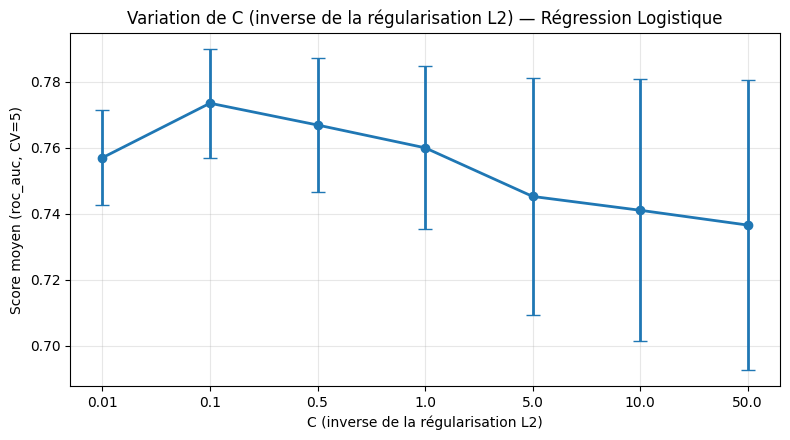

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

def variation(fabrique_modele, nom_param, valeurs, X, y, scoring='roc_auc', cv=5):
    scores_moyens = []
    scores_ecart = []

    for v in valeurs:
        modele = fabrique_modele(v)
        cv_res = cross_val_score(modele, X, y, cv=cv, scoring=scoring)
        scores_moyens.append(cv_res.mean())
        scores_ecart.append(cv_res.std())

    scores_moyens = np.array(scores_moyens)
    scores_ecart = np.array(scores_ecart)

    meilleur_idx = np.argmax(scores_moyens)
    print(f"Meilleure valeur pour {nom_param} : {valeurs[meilleur_idx]} (score moyen {scoring} = {scores_moyens[meilleur_idx]:.4f})")

    plt.figure(figsize=(8, 4.5))
    plt.errorbar(
        range(len(valeurs)), scores_moyens, yerr=scores_ecart,
        fmt='o-', capsize=5, linewidth=2, color='#1f77b4'
    )
    plt.xticks(range(len(valeurs)), [str(v) for v in valeurs])
    plt.xlabel(nom_param)
    plt.ylabel(f"Score moyen ({scoring}, CV={cv})")
    plt.title(f"Variation de {nom_param} — Régression Logistique")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

variation(
    lambda c: Pipeline([
        ('prep', preproc),
        ('clf', LogisticRegression(C=c, max_iter=1000, random_state=42))
    ]),
    'C (inverse de la régularisation L2)',
    [0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0],
    X_train,
    y_train,
    scoring='roc_auc'
)

**Interprétation.** Le meilleur AUC en validation croisée est obtenu pour *C* = 0,1 (0,7735). Une régularisation trop forte (*C* = 0,01, AUC 0,757) sous-apprend, tandis qu'au-delà de *C* = 1 le score baisse (0,737 pour *C* = 50) et son écart-type entre plis triple (de 0,014 à 0,044) : le modèle suit alors le bruit de l'entraînement. L'écart entre *C* = 0,1, 0,5 et 1 reste inférieur à l'écart-type entre plis : le choix est peu sensible dans cette zone. Nous retenons *C* = 0,1, qui est la valeur utilisée pour le modèle final.

## 4. Analyse des résultats et synthèse

### 4.1 Attributs déterminants du risque de crédit

L'examen des coefficients de la régression logistique (*C* = 0,1) permet de répondre à la problématique métier. Les rapports de cotes (*odds ratios*) se lisent à autres variables constantes, par rapport à la modalité de référence ; pour la durée, variable standardisée, ils se lisent pour une augmentation d'un écart-type (environ 12 mois).

- **Facteurs aggravants** ($w_j > 0$, odds ratio > 1) : une épargne inférieure à 100 DM (×1,51), un crédit destiné à la formation (×1,50), un compte courant à solde négatif (×1,47), l'absence de bien connu (×1,39) et une durée de prêt élevée (×1,34).
- **Facteurs protecteurs** ($w_j < 0$, odds ratio < 1) : l'absence de compte courant (×0,42), un historique de crédit « critique avec autres crédits existants » (×0,56), l'absence d'autre plan de paiement (×0,62), un crédit pour voiture d'occasion (×0,66) et une épargne inconnue (×0,66).

Les deux facteurs protecteurs les plus forts sont contre-intuitifs : les clients sans compte courant ou avec un historique « critique » sont moins souvent en défaut. Cela peut refléter la politique de sélection de la banque plutôt qu'une absence de risque réelle.

### 4.2 Analyse de la courbe de coût et sensibilité du seuil

- **Pouvoir discriminant (AUC) :** le modèle obtient une AUC de 0,811 sur le test (0,7735 en validation croisée), ce qui montre une bonne capacité à classer les dossiers risqués au-dessus des dossiers sains, indépendamment du seuil.
- **Références naïves :** au ratio 5:1, « tout accepter » coûte 375 et « tout refuser » coûte 175. La meilleure référence est donc 175.
- **Inefficacité du seuil standard (*s* = 0,50) :** avec ce seuil, le coût du modèle est de 201 au ratio 5:1, soit **plus que « tout refuser »** : le modèle laisse passer trop de mauvais dossiers (faux négatifs) alors qu'ils coûtent 5 fois plus cher.
- **Seuil optimal et sensibilité :** le seuil est choisi par validation croisée sur l'entraînement, puis évalué une seule fois sur le test. Pour le ratio de référence 5:1, on obtient *s* = 0,16 et un coût de 138, soit environ 31 % de moins qu'à *s* = 0,50 et 21 % de moins que la meilleure référence naïve. Pour 3:1, *s* = 0,25 (coût 104) ; pour 8:1, *s* = 0,12 (coût 148). Ces seuils sont proches du repère théorique $s_{th} = \dfrac{C_{FP}}{C_{FP}+C_{FN}}$, qui vaut 0,25, 0,17 et 0,11. Le seuil optimal baisse quand le coût du défaut augmente : la politique d'octroi devient plus stricte.

- **Comparaison avec la forêt aléatoire :** elle obtient une AUC de 0,799 sur le test (0,792 en validation croisée, mais 0,988 sur l'entraînement : surapprentissage) et un coût de 120 à *s* = 0,23, contre 138 pour la régression logistique. Sur 250 dossiers, cet écart n'est pas concluant ; la régression logistique est retenue pour son interprétabilité.

### 4.3 Impact de la régularisation (hyperparamètre *C*)

La variation de *C* en validation croisée montre qu'une régularisation trop forte (*C* = 0,01, AUC 0,757) sous-apprend. Le meilleur score est obtenu pour *C* = 0,1 (0,7735). Au-delà de *C* = 1, le score baisse (0,737 pour *C* = 50) et l'écart-type entre plis triple (de 0,014 à 0,044) : le modèle suit le bruit de l'entraînement. Entre *C* = 0,1 et *C* = 1, l'écart reste inférieur à l'écart-type : le choix est peu sensible dans cette zone.

### 4.4 Limites et pistes d'amélioration

- **Limites :** un seul jeu de test de 250 dossiers (75 mauvais risques), donc des coûts bruités ; des ratios de coûts supposés et non issus des pertes réelles d'une banque ; des données anciennes (1994) ; la présence de variables sensibles (statut personnel, âge, travailleur étranger) qui pose un risque d'équité.
- **Améliorations :** calibrer les probabilités (méthode de Platt), comparer d'autres modèles (arbres, boosting), utiliser les coûts réels de la banque, réaliser un audit d'équité et expliquer chaque refus (valeurs de Shapley).

## 5. Conclusion
**Réponse à la problématique.** Les attributs qui augmentent le risque sont
l'épargne < 100 DM (×1,51), un crédit de formation (×1,50), un compte courant
à solde négatif (×1,47) et une durée élevée (×1,34). L'absence de compte courant
est protectrice (×0,42), sans doute par effet de sélection de la banque.
Au ratio 5:1, la meilleure référence naïve est « tout refuser » (175). Le seuil
standard 0,50 est inefficace (201 > 175). Avec le seuil choisi par validation
croisée (0,16), la régression logistique coûte 138 sur le test : le critère de
réussite est atteint (−21 % vs la meilleure référence, −31 % vs s = 0,50).
**Choix du modèle.** La forêt (s = 0,23) coûte 120, mais son AUC train (0,988)
contre 0,799 en test révèle un surapprentissage, et l'écart de 18 unités sur
250 dossiers (75 mauvais risques) est trop bruité pour être concluant. Nous
retenons la régression logistique : interprétable, stable, justifiable.
**Limites.** Voir 4.4 (test de 250 dossiers, coûts supposés, données de 1994,
variables sensibles).